In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
sns.set_theme(style='whitegrid', context='notebook')
df = pd.read_csv('collisions_merged_clean.csv', low_memory=False)

In [3]:
# Map codes to readable labels
sev_map = {1: 'Fatal', 2: 'Serious', 3: 'Slight'}
weather_map = {
    1: 'Fine (no high winds)', 2: 'Raining (no high winds)', 3: 'Snowing (no high winds)',
    4: 'Fine + high winds', 5: 'Raining + high winds', 6: 'Snowing + high winds',
    7: 'Fog or mist', 8: 'Other'
}
light_map = {
    1: 'Daylight', 4: 'Darkness - lights lit', 5: 'Darkness - lights unlit',
    6: 'Darkness - no lighting', 7: 'Darkness - lighting unknown'
}
surface_map = {
    1: 'Dry', 2: 'Wet or damp', 3: 'Snow', 4: 'Frost or ice', 5: 'Flood (>3cm)'
}
day_map = {1: 'Sun', 2: 'Mon', 3: 'Tue', 4: 'Wed', 5: 'Thu', 6: 'Fri', 7: 'Sat'}

df['severity_label'] = df['collision_severity'].map(sev_map)
df['weather_label'] = df['weather_conditions'].map(weather_map)
df['light_label'] = df['light_conditions'].map(light_map)
df['surface_label'] = df['road_surface_conditions'].map(surface_map)
df['day_name'] = df['day_of_week'].map(day_map)
df['is_ksi'] = df['collision_severity'].isin([1, 2]).astype(int)  # 1 = Fatal or Serious

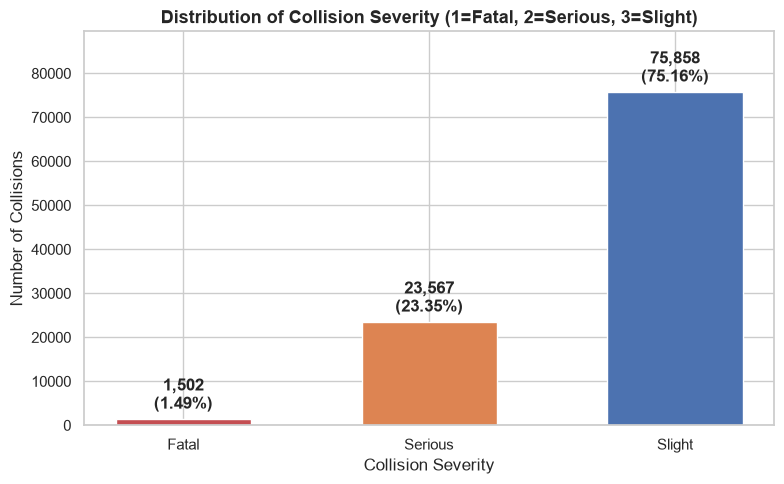

In [4]:
# =========================================================
# 1. Plot the distribution of collision_severity (1=Fatal, 2=Serious, 3=Slight)
# =========================================================
sev_order = ['Fatal', 'Serious', 'Slight']
sev_counts = df['severity_label'].value_counts().reindex(sev_order)
sev_pct = (sev_counts / len(df) * 100).round(2)

plt.figure(figsize=(8, 5))
bars = plt.bar(sev_order, sev_counts.values, color=['#C44E52', '#DD8452', '#4C72B0'], width=0.55)
for bar, count, pct in zip(bars, sev_counts.values, sev_pct.values):
    plt.text(bar.get_x() + bar.get_width() / 2, count + 1200,
             f'{count:,}\n({pct:.2f}%)', ha='center', va='bottom', fontweight='bold')

plt.title('Distribution of Collision Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=13, fontweight='bold')
plt.xlabel('Collision Severity')
plt.ylabel('Number of Collisions')
plt.ylim(0, sev_counts.max() * 1.18)
plt.tight_layout()
plt.show()

 Statistical Insights from Collision Severity Distribution (N = 100,927):
 1. Severe Class Imbalance (~50.5:1 Slight-to-Fatal Ratio):
    - Slight (75,858 | 75.16%) dominates the dataset, followed by Serious (23,567 | 23.35%),
      while Fatal (1,502 | 1.49%) represents a rare minority class (~1 in 67 collisions).
 2. Combined KSI Baseline (24.84%):
    - Nearly 1 in 4 collisions (25,069 incidents) results in a Killed or Seriously Injured (KSI) outcome,
      providing a more balanced binary target (24.84% vs. 75.16%) than 3-class prediction alone.
 3. Modeling & Evaluation Implications:
    - Raw accuracy is misleading here (a dummy model predicting "Slight" achieves 75.16% accuracy).
    - Downstream models should use stratified train/test splits, class weighting or SMOTE/resampling

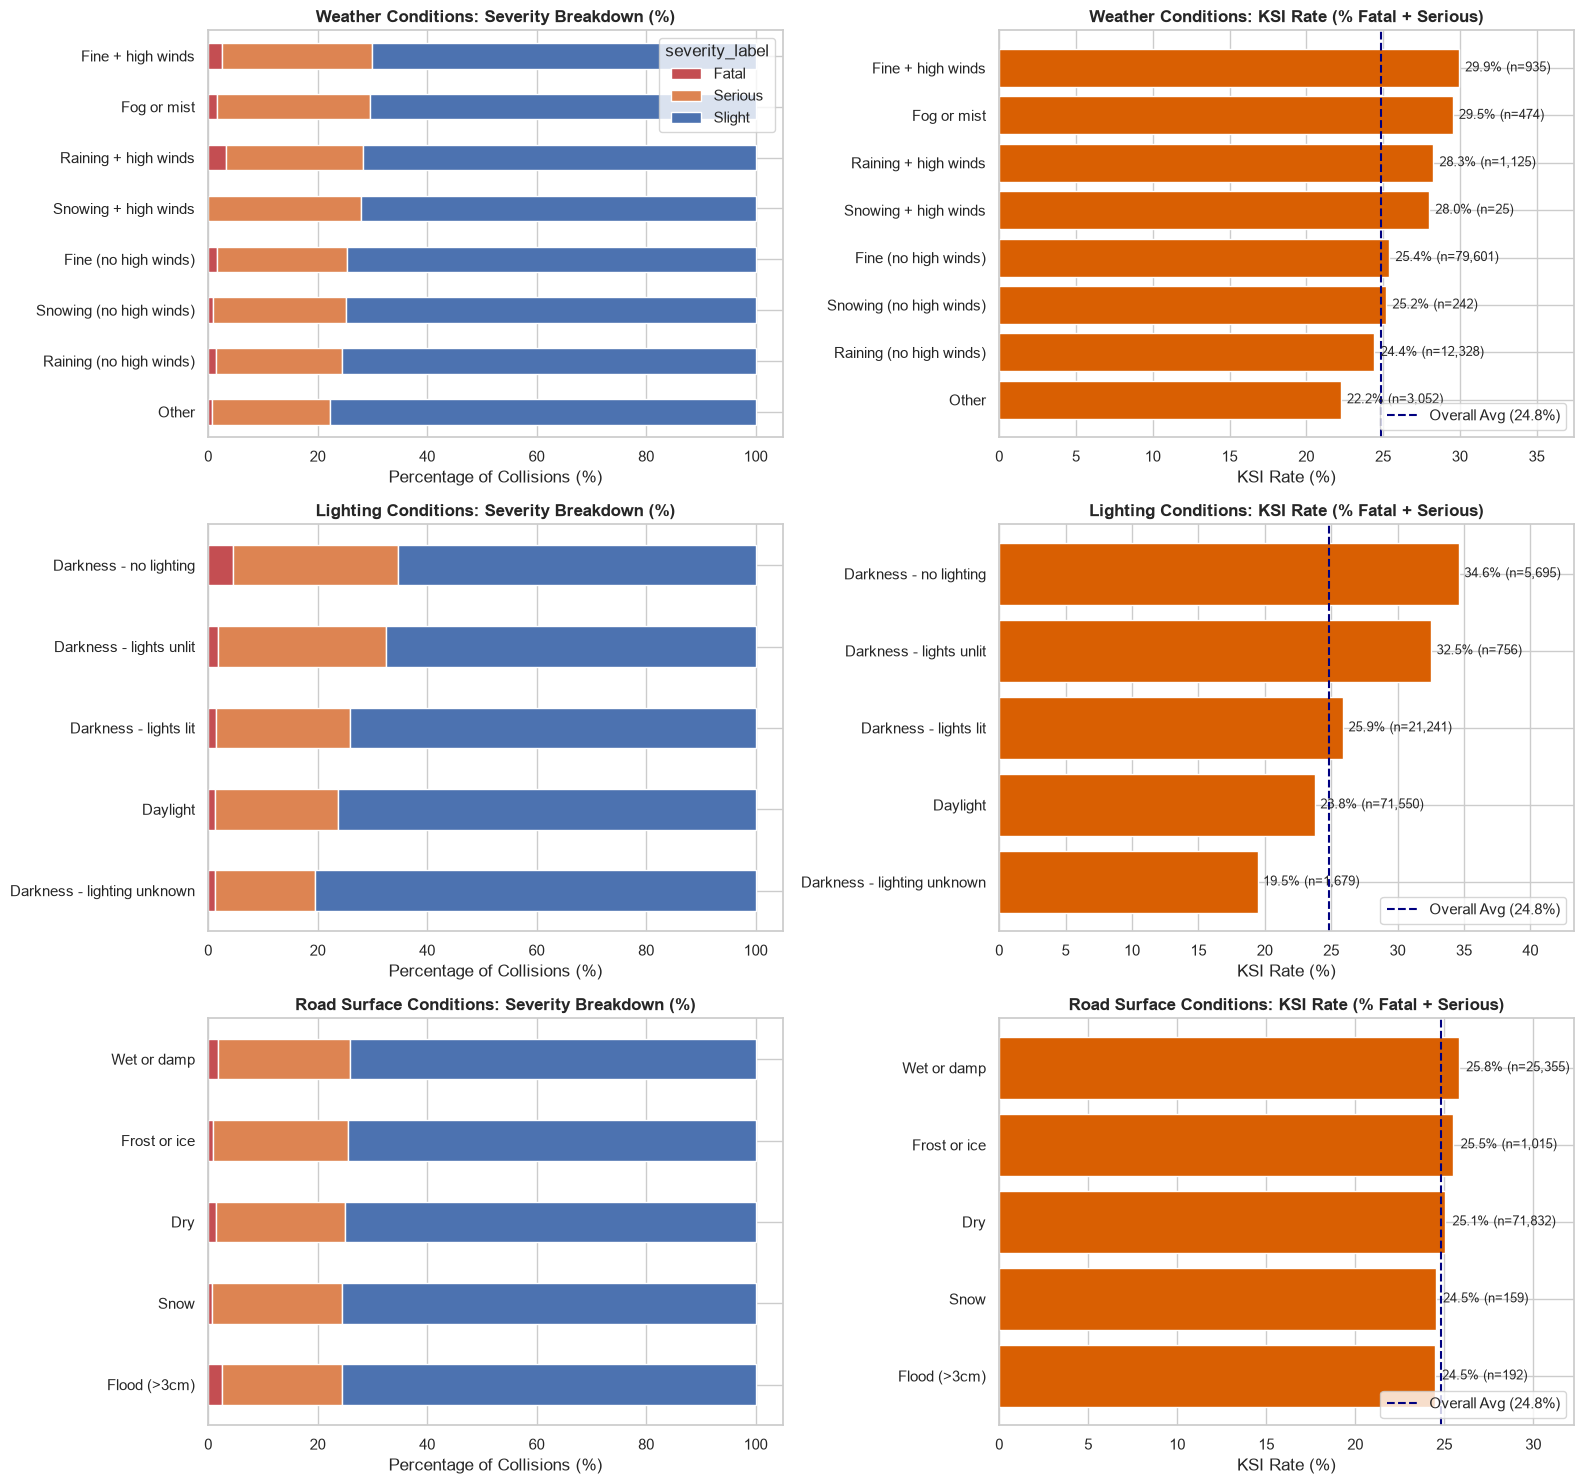

In [5]:
# =========================================================
# 2. Graphs for Severity vs. Weather, Lighting, and Road Surface
# =========================================================
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
env_cols = [
    ('weather_label', 'Weather Conditions'),
    ('light_label', 'Lighting Conditions'),
    ('surface_label', 'Road Surface Conditions')
]
avg_ksi = df['is_ksi'].mean() * 100

for i, (col, title) in enumerate(env_cols):
    sub = df.dropna(subset=[col])
    pct = pd.crosstab(sub[col], sub['severity_label'], normalize='index')[['Fatal', 'Serious', 'Slight']] * 100
    pct['KSI_Rate'] = pct['Fatal'] + pct['Serious']
    pct['Count'] = sub[col].value_counts()
    pct = pct.sort_values('KSI_Rate', ascending=True)

    # Left: 100% stacked severity breakdown
    pct[['Fatal', 'Serious', 'Slight']].plot(
        kind='barh', stacked=True, ax=axes[i, 0],
        color=['#C44E52', '#DD8452', '#4C72B0']
    )
    axes[i, 0].set_title(f'{title}: Severity Breakdown (%)', fontweight='bold')
    axes[i, 0].set_xlabel('Percentage of Collisions (%)')
    axes[i, 0].set_ylabel('')
    if i > 0:
        axes[i, 0].get_legend().remove()


# Right: KSI Rate (% Fatal + Serious)
    bars = axes[i, 1].barh(pct.index, pct['KSI_Rate'], color='#D95F02')
    axes[i, 1].axvline(avg_ksi, color='navy', linestyle='--', label=f'Overall Avg ({avg_ksi:.1f}%)')
    axes[i, 1].set_title(f'{title}: KSI Rate (% Fatal + Serious)', fontweight='bold')
    axes[i, 1].set_xlabel('KSI Rate (%)')
    axes[i, 1].set_xlim(0, pct['KSI_Rate'].max() * 1.25)
    axes[i, 1].legend(loc='lower right')

    for bar, (_, row) in zip(bars, pct.iterrows()):
        axes[i, 1].text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
                        f"{row['KSI_Rate']:.1f}% (n={int(row['Count']):,})", va='center', fontsize=9)

plt.tight_layout()
plt.show()

The statistical insights this part explains is the effect of various features on the severity of road accidents in Nigeria.
 Statistical Insights: Severity vs. Environmental Conditions (All Chi-Square p < 0.01):
 1. Lighting is the Strongest Environmental Predictor (Chi2 = 670.85, Cramér's V = 0.0577):
   - Unlit darkness spikes KSI risk to 34.6% (4.58% fatal—over 3.6x the 1.25% daylight fatal rate).
 2. High Winds & Fog Drive Weather Risk, Not Light Rain (Chi2 = 69.54, Cramér's V = 0.0189):
    - Standard rain (24.4% KSI) is slightly less severe than fine weather (25.4% KSI) due to slower speeds;
      severity only jumps in high winds (30.0% KSI) and fog/mist (29.5% KSI).
 3. Road Surface Has Minimal Direct Effect (Chi2 = 21.06, Cramér's V = 0.0103):
    - KSI rates stay nearly flat across Wet (25.8%), Frost/Ice (25.5%), and Dry (25.1%) surfaces,
      making lighting and wind/visibility far stronger modeling features than surface condition alone.

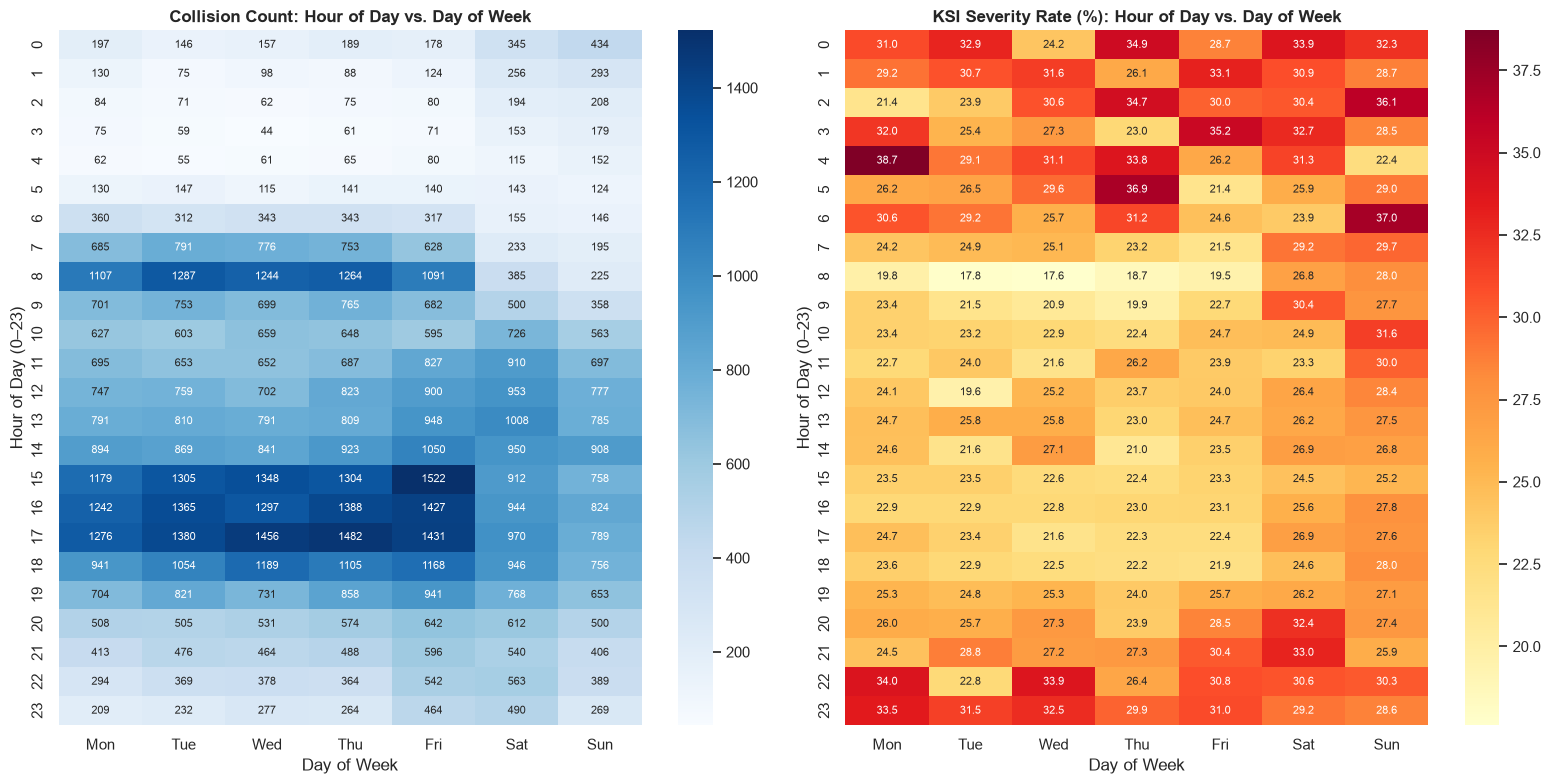

In [6]:
# =========================================================
# 3. Temporal Heatmap (Hour of Day vs. Day of Week)
# =========================================================
day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
piv_count = df.pivot_table(index='hour', columns='day_name', values='collision_severity', aggfunc='count')[day_order]
piv_ksi = df.pivot_table(index='hour', columns='day_name', values='is_ksi', aggfunc='mean')[day_order] * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.heatmap(piv_count, cmap='Blues', annot=True, fmt='d', ax=axes[0], annot_kws={'size': 8})
axes[0].set_title('Collision Count: Hour of Day vs. Day of Week', fontweight='bold')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Hour of Day (0–23)')

sns.heatmap(piv_ksi, cmap='YlOrRd', annot=True, fmt='.1f', ax=axes[1], annot_kws={'size': 8})
axes[1].set_title('KSI Severity Rate (%): Hour of Day vs. Day of Week', fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Hour of Day (0–23)')

plt.tight_layout()
plt.show()

 Statistical Insights: Temporal Heatmap (Hour of Day vs. Day of Week):
 1. Volume vs. Severity Inversion:
    - Collision counts peak during weekday rush hours (Fri 15:00 = 1,522; Thu 17:00 = 1,482),
      yet those same commute hours have the lowest KSI rates (17.6%–23.3%) due to traffic congestion slowing speeds.
 2. Late-Night & Early-Morning Severity Spike (00:00–06:00):
   - KSI rates surge above 30%–38% overnight (e.g., Mon 04:00 = 38.7%, Sun 06:00 = 37.0%, Sun 02:00 = 36.1%),
      driven by higher free-flowing speeds, darkness, fatigue, and alcohol/impairment.
 3. Weekend Risk Shift:
    - Weekends have fewer total collisions than weekdays, but a higher overall KSI rate (27.7% vs. 23.9%),
      with elevated severity extending across Saturday and Sunday daytime hours (25%–32% KSI).

In [7]:
# =========================================================
# 4. Patterns & Recommended Features for the Model
# =========================================================
# Engineered features based on EDA patterns
df['is_unlit_darkness'] = df['light_conditions'].isin([5, 6]).astype(int)
df['is_high_speed_single_carriageway'] = ((df['speed_limit'] >= 60) & (df['road_type'] == 6)).astype(int)
df['is_late_night'] = df['hour'].isin([22, 23, 0, 1, 2, 3, 4]).astype(int)
df['high_wind_or_fog'] = df['weather_conditions'].isin([4, 5, 6, 7]).astype(int)
df['casualties_per_vehicle'] = df['number_of_casualties'] / df['number_of_vehicles']
df['vehicle_data_missing'] = df['has_motorcycle'].isna().astype(int)

# Final recommended feature list for modeling
recommended_features = [
    'speed_limit', 'urban_or_rural_area', 'road_type', 'first_road_class',
    'junction_detail', 'number_of_vehicles', 'number_of_casualties',
    'light_conditions', 'weather_conditions', 'hour', 'day_of_week',
    'is_weekend', 'is_peak', 'month',
    'has_motorcycle', 'any_skidding', 'has_hgv', 'has_pedal_cycle',
    'any_escooter', 'min_driver_age', 'max_driver_age',
    'is_unlit_darkness', 'is_high_speed_single_carriageway', 'is_late_night',
    'high_wind_or_fog', 'casualties_per_vehicle', 'vehicle_data_missing'
]

print("Recommended features ready:", len(recommended_features))

Recommended features ready: 27


 Summary of Feature Selection & Engineering Rationale:
 1. Engineered High-Risk Interaction Features (Isolate Deadly EDA Patterns):
    - is_unlit_darkness: Captures unlit night roads where KSI jumps to 34.4% (4.25% fatal).
    - is_high_speed_single_carriageway: Isolates >=60 mph single carriageways (deadliest road type: 35.7% KSI, 3.92% fatal).
    - is_late_night: Flags 22:00–04:59 overnight crashes where fatality rate more than doubles (2.84% vs. 1.34%).
    - high_wind_or_fog: Separates genuine wind/visibility hazards (29.1% KSI) from light rain (which has no severity spike).
    - casualties_per_vehicle: Distinguishes high-occupancy single-vehicle crashes from multi-car urban fender-benders.
    - vehicle_data_missing: Flags the ~35% rows missing vehicle-table joins (27.1% KSI) instead of dropping 35k+ records.

 2. Raw Features Retained (Strongest Statistical Signal):
    - Speed & road geometry (speed_limit, urban_or_rural_area, road_type, junction_detail),
      lighting/time (light_conditions, hour, is_weekend), and vehicle/driver risk (has_motorcycle, any_skidding, has_hgv, driver ages).

 3. Excluded Features (Leakage, Overfitting, or Extreme Sparsity):
    - Dropped did_police_officer_attend_scene_of_accident (target leakage: police attend because injuries are severe),
      unique IDs / high-cardinality road numbers (overfitting), and >40% missing columns (special_conditions_at_site, junction_control).